In [16]:
import matplotlib.pyplot as plt
import numpy as np

In [44]:
## Parameters 
N = 256 ## Grid size  
Du, Dv, dt = 0.2, 0.1, 1.0
F, k = 0.035, 0.065 ## Feed rate and kill rate

## Seed for random number generator
rng = np.random.default_rng(0)

In [45]:
## Concentration of U and V in each cell 
U = np.ones((N, N))  ## Initially U is one everywhere 
V = np.zeros((N, N))  ## and V is zero everywhere 



## Except, in the center of the grid, there will be a mix of U and V 

## let c be the center point of the grid
c = N // 2 
## Then we slice the center grid 
center_grid = (slice(c - 10, c + 10), slice(c - 10, c + 10))   # 20x20 block
U *= rng.uniform(0.95, 1.05, size=(N, N))
V *= rng.uniform(0.95, 1.05, size=(N, N))


## This center grid will have mixed values of U and V 
V[center_grid] = rng.uniform(0.2, 0.3, size = (20, 20)) 
U[center_grid] = 1 - 2 * V[center_grid]


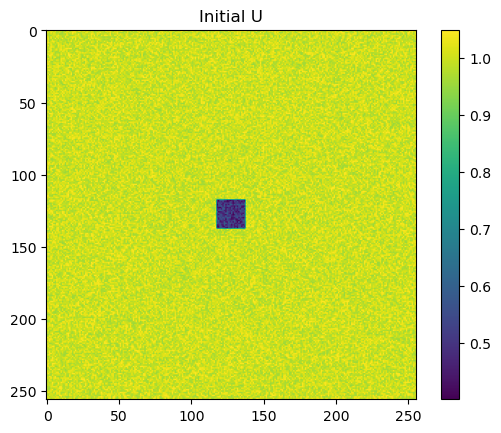

In [46]:
# This code diplays the grid we set in the previous code chunk 
plt.imshow(U, cmap="viridis")
plt.colorbar()
plt.title("Initial U")
plt.show()

In [47]:
## Laplacian function that calculates the average concentration of a cell's neigbours 
def laplacian(Z):
    return (np.roll(Z,  1, axis=0) +   # neighbour above
            np.roll(Z, -1, axis=0) +   # neighbour below
            np.roll(Z,  1, axis=1) +   # neighbour left
            np.roll(Z, -1, axis=1) -   # neighbour right
            4 * Z)

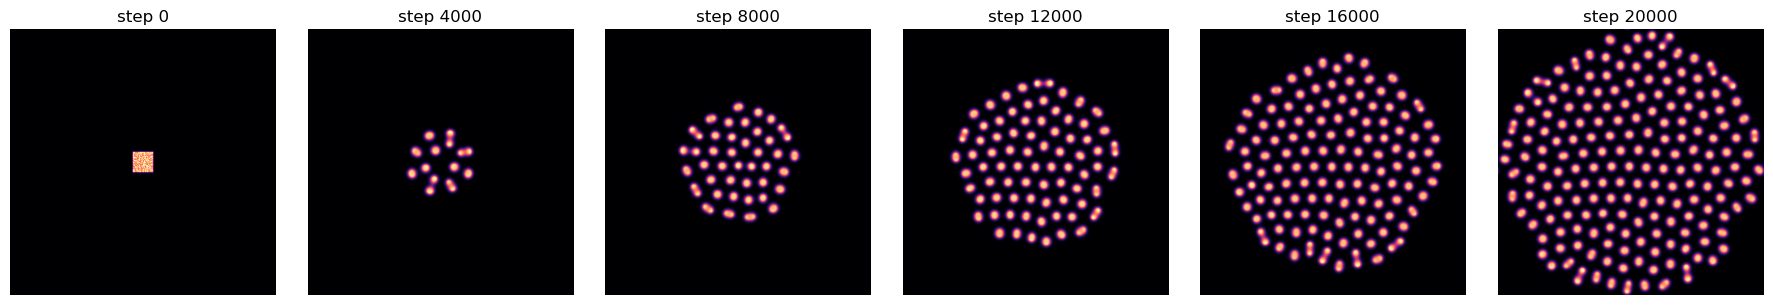

V range: 2.8244225051942154e-25 0.4029879776164055


In [48]:
def step(U, V):
    lapU = laplacian(U)
    lapV = laplacian(V)
    uvv = U * V * V                      # the reaction term UV^2, computed once

    U_new = U + dt * (Du * lapU - uvv + F * (1 - U))
    V_new = V + dt * (Dv * lapV + uvv - (F + k) * V)
    return U_new, V_new


# --- Run the simulation, keeping snapshots along the way ---
n_steps = 20000
snap_every = 4000
snapshots = []

for i in range(n_steps + 1):
    if i % snap_every == 0:
        snapshots.append((i, V.copy()))
    U, V = step(U, V)

    # stop early if the simulation becomes unstable
    if not np.isfinite(V).all():
        print("Blew up at step", i)
        break

# --- Show the snapshots side by side ---
fig, axes = plt.subplots(1, len(snapshots), figsize=(3 * len(snapshots), 3))
for ax, (i, snap) in zip(axes, snapshots):
    ax.imshow(snap, cmap="magma")
    ax.set_title(f"step {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("V range:", V.min(), V.max())

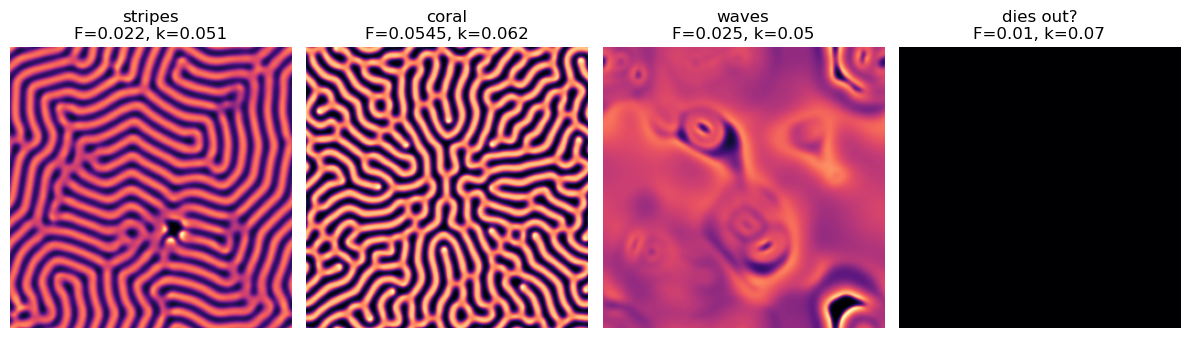

In [49]:
import os
os.makedirs("figures", exist_ok=True)

def step(U, V, F, k):
    lapU = laplacian(U)
    lapV = laplacian(V)
    uvv = U * V * V
    U_new = U + dt * (Du * lapU - uvv + F * (1 - U))
    V_new = V + dt * (Dv * lapV + uvv - (F + k) * V)
    return U_new, V_new

def initial_state(seed=0):
    rng = np.random.default_rng(seed)
    U = np.ones((N, N))
    V = np.zeros((N, N))
    c = N // 2
    sq = (slice(c - 10, c + 10), slice(c - 10, c + 10))
    V[sq] = rng.uniform(0.2, 0.3, size=(20, 20))
    U[sq] = 1 - 2 * V[sq]
    U *= rng.uniform(0.99, 1.01, size=(N, N))
    V *= rng.uniform(0.99, 1.01, size=(N, N))
    return U, V

def run(F, k, n_steps=30000, seed=0):
    U, V = initial_state(seed)
    for i in range(n_steps):
        U, V = step(U, V, F, k)
    if not np.isfinite(V).all():
        print(f"F={F}, k={k}: blew up")
    return U, V

# --- A few known parameter values ---
params = [
    (0.022, 0.051, "stripes"),
    (0.0545, 0.062, "coral"),
    (0.025, 0.050, "waves"),
    (0.010, 0.070, "dies out?"),
]

fig, axes = plt.subplots(1, len(params), figsize=(3 * len(params), 3.3))
for ax, (F_, k_, name) in zip(axes, params):
    U_, V_ = run(F_, k_)
    plt.imsave(f"figures/gs_F{F_:.4f}_k{k_:.4f}.png", V_, cmap="magma")
    ax.imshow(V_, cmap="magma")
    ax.set_title(f"{name}\nF={F_}, k={k_}")
    ax.axis("off")
plt.tight_layout()
plt.show()